# Projeto 3 — Resultados dos seis treinamentos

**Autores:** Paulo Henrico Rabelo (2312652) e Joey Alan (2320416)

Lê apenas os arquivos gerados por `scripts/treinar.py`, `scripts/prever.py` e `scripts/avaliar.py`; nada é treinado aqui.
O teste só aparece depois de `scripts/prever.py --teste`, executado uma vez ao fim das escolhas.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as Show, display
from PIL import Image

from projeto3.classes import CLASSES, NOMES_PT

FIG = ROOT / "resultados" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
FONTE = "Fonte: elaborado pelos autores a partir do NWPU-RESISC45 (Cheng; Han; Lu, 2017)."
pd.set_option("display.width", 140)


def salvar(fig, nome):
    fig.text(0.01, 0.003, FONTE, fontsize=7, color="0.35")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(FIG / nome, dpi=150)
    plt.show()

experimentos = pd.read_csv(ROOT / "resultados/experimentos.csv")
arquiteturas = pd.read_csv(ROOT / "resultados/arquiteturas.csv")
tem_teste = "f1_macro_teste" in experimentos
print("Teste avaliado:", tem_teste)

Teste avaliado: True


## Arquiteturas e parâmetros

In [2]:
for experimento in arquiteturas["experimento"]:
    print((ROOT / "resultados/arquiteturas" / f"{experimento}.txt").read_text(encoding="utf-8"))
arquiteturas

Modelo: MLP_A_128
camada          tipo                      saída                   parâmetros
----------------------------------------------------------------------------
imagem_rgb      InputLayer                128 x 128 x 3                    0
vetor           Flatten                   49152                            0
densa1          Dense                     256                     12.582.912
bn1             BatchNormalization        256                          1.024
relu1           ReLU                      256                              0
dropout1        Dropout                   256                              0
classe          Dense                     10                           2.570
----------------------------------------------------------------------------
Total de parâmetros: 12.586.506
Treináveis: 12.585.994 | não treináveis (médias/variâncias do BatchNorm): 512

Modelo: MLP_B_128
camada          tipo                      saída                   parâmetros
------

,experimento,familia,variante,resolucao,camadas,parametros,parametros_treinaveis
0,MLP-A-128,MLP,A,128,6,12586506,12585994
1,MLP-B-128,MLP,B,128,14,12626314,12625418
2,CNN-A-128,CNN,A,128,15,95210,94762
3,CNN-B-128,CNN,B,128,20,424042,423082
4,CNN-A-256,CNN,A,256,15,95210,94762
5,CNN-B-256,CNN,B,256,20,424042,423082


## Desempenho e custo

In [3]:
colunas = ["experimento", "parametros", "tamanho_modelo_mb", "lote", "epocas_executadas", "checkpoint_epoca",
           "tempo_total_s", "tempo_medio_epoca_s", "dispositivo", "acuracia_validacao", "f1_macro_validacao"]
if tem_teste:
    colunas += ["acuracia_teste", "f1_macro_teste", "precisao_macro_teste", "recall_macro_teste", "classes_sem_previsao_teste"]
experimentos[colunas]

,experimento,parametros,tamanho_modelo_mb,lote,epocas_executadas,checkpoint_epoca,tempo_total_s,tempo_medio_epoca_s,dispositivo,acuracia_validacao,f1_macro_validacao,acuracia_teste,f1_macro_teste,precisao_macro_teste,recall_macro_teste,classes_sem_previsao_teste
0,MLP-A-128,12586506,48.04,8,11,7,96.5,8.6,NVIDIA GeForce RTX 2050,0.5529,0.5409,0.5429,0.5295,0.5300,0.5429,NaN
1,MLP-B-128,12626314,48.22,8,12,12,118.2,9.7,NVIDIA GeForce RTX 2050,0.5663,0.5325,0.5571,0.5261,0.5395,0.5571,NaN
2,CNN-A-128,95210,0.42,8,12,8,157.1,13.0,NVIDIA GeForce RTX 2050,0.8217,0.8169,0.8095,0.8041,0.8254,0.8095,NaN
3,CNN-B-128,424042,1.69,8,12,10,182.3,15.1,NVIDIA GeForce RTX 2050,0.8198,0.8195,0.8390,0.8410,0.8564,0.8390,NaN
4,CNN-A-256,95210,0.42,8,12,11,380.3,31.7,NVIDIA GeForce RTX 2050,0.8141,0.8067,0.8143,0.8095,0.8198,0.8143,NaN
5,CNN-B-256,424042,1.69,8,12,10,434.6,36.1,NVIDIA GeForce RTX 2050,0.8160,0.8170,0.8200,0.8204,0.8377,0.8200,NaN


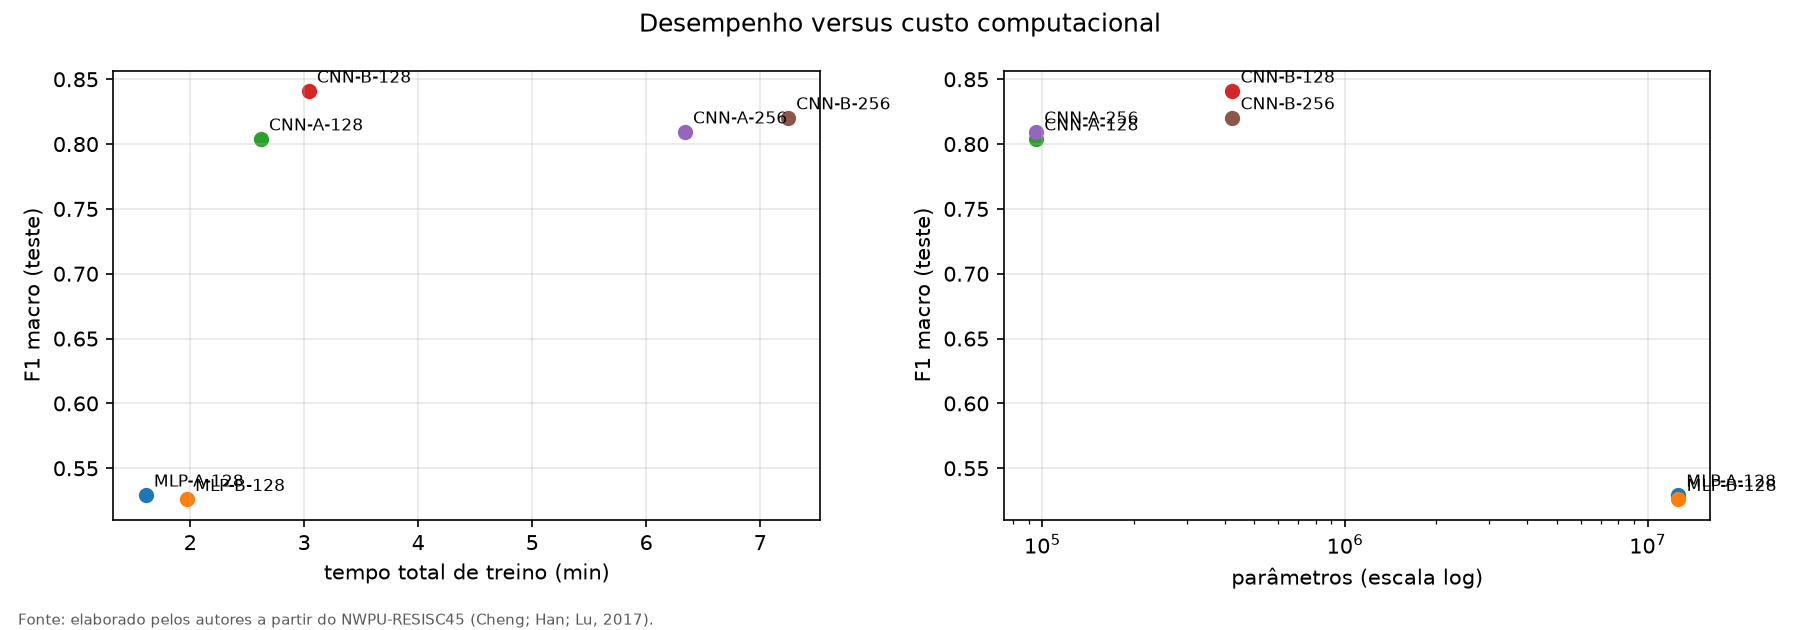

In [4]:
alvo = "teste" if tem_teste else "validacao"
display(Show(FIG / f"desempenho_custo_{alvo}.png"))

## Curvas de aprendizagem (checkpoint marcado em vermelho)

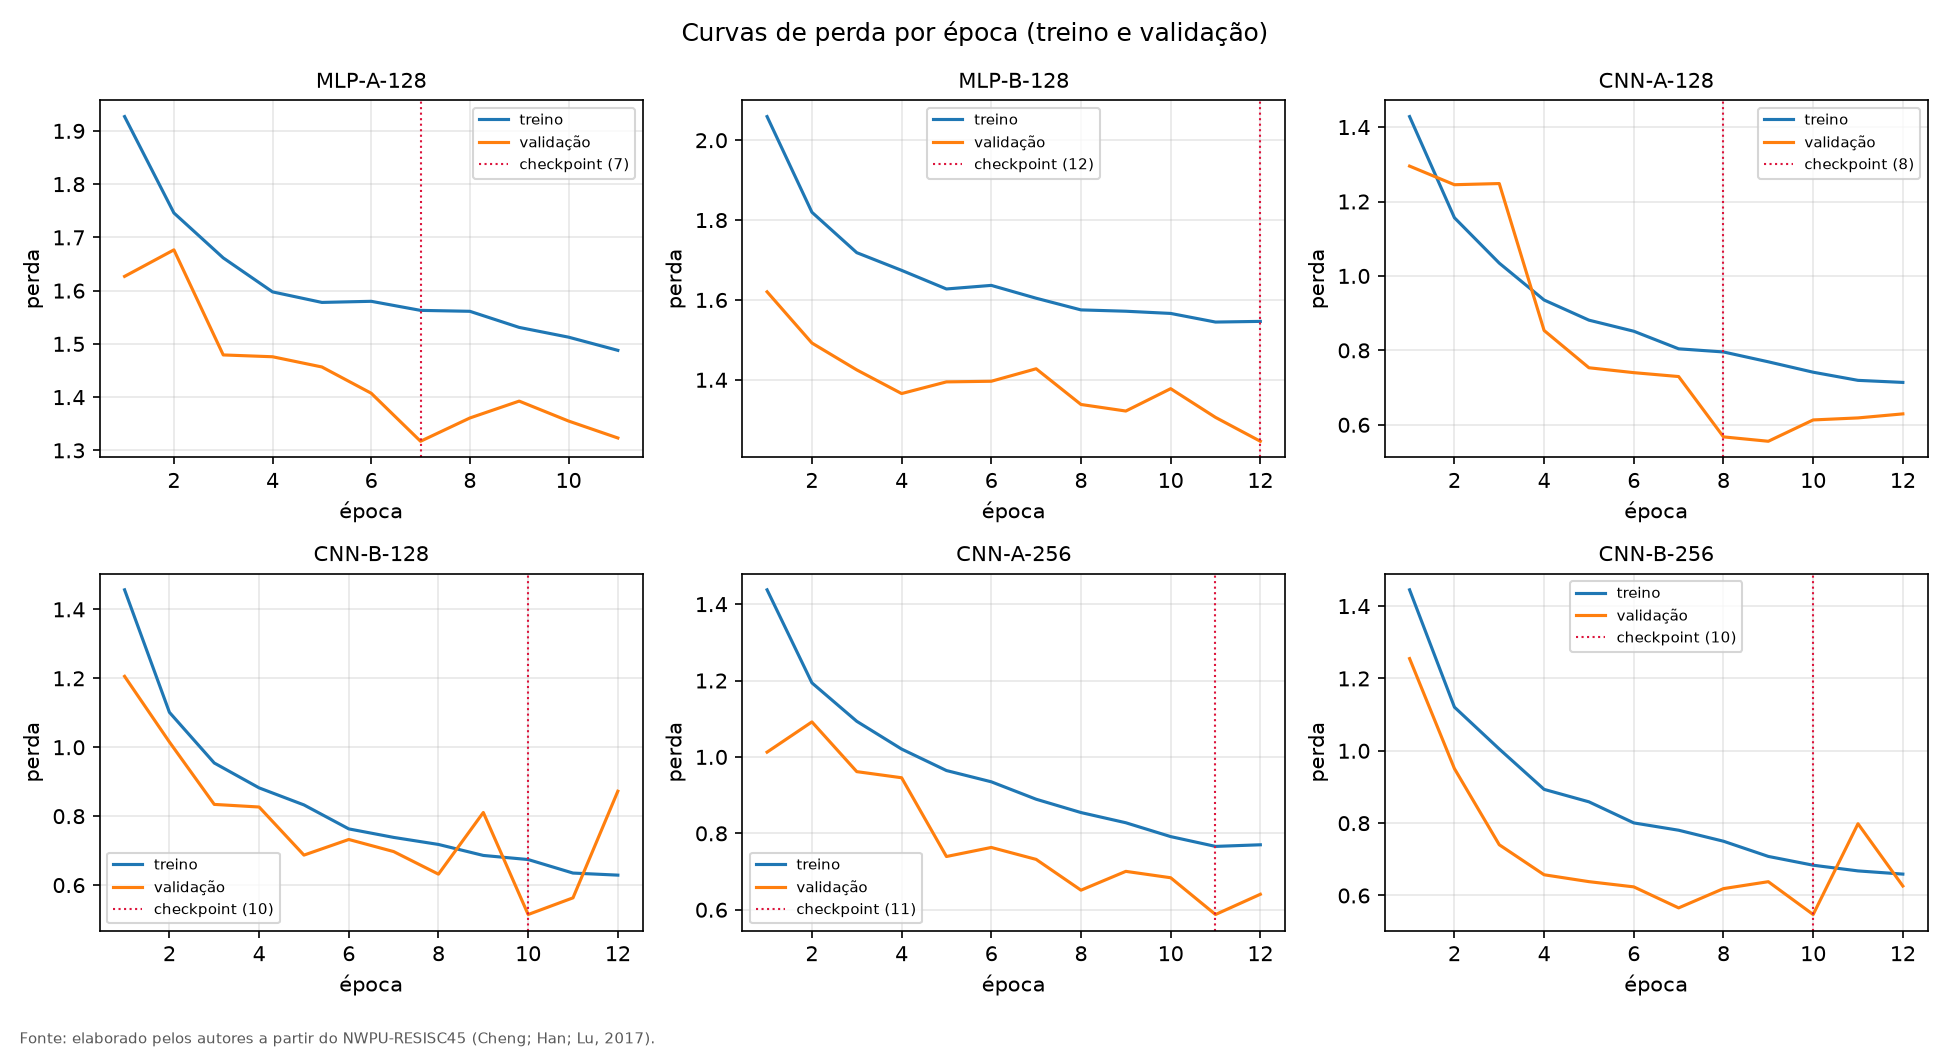

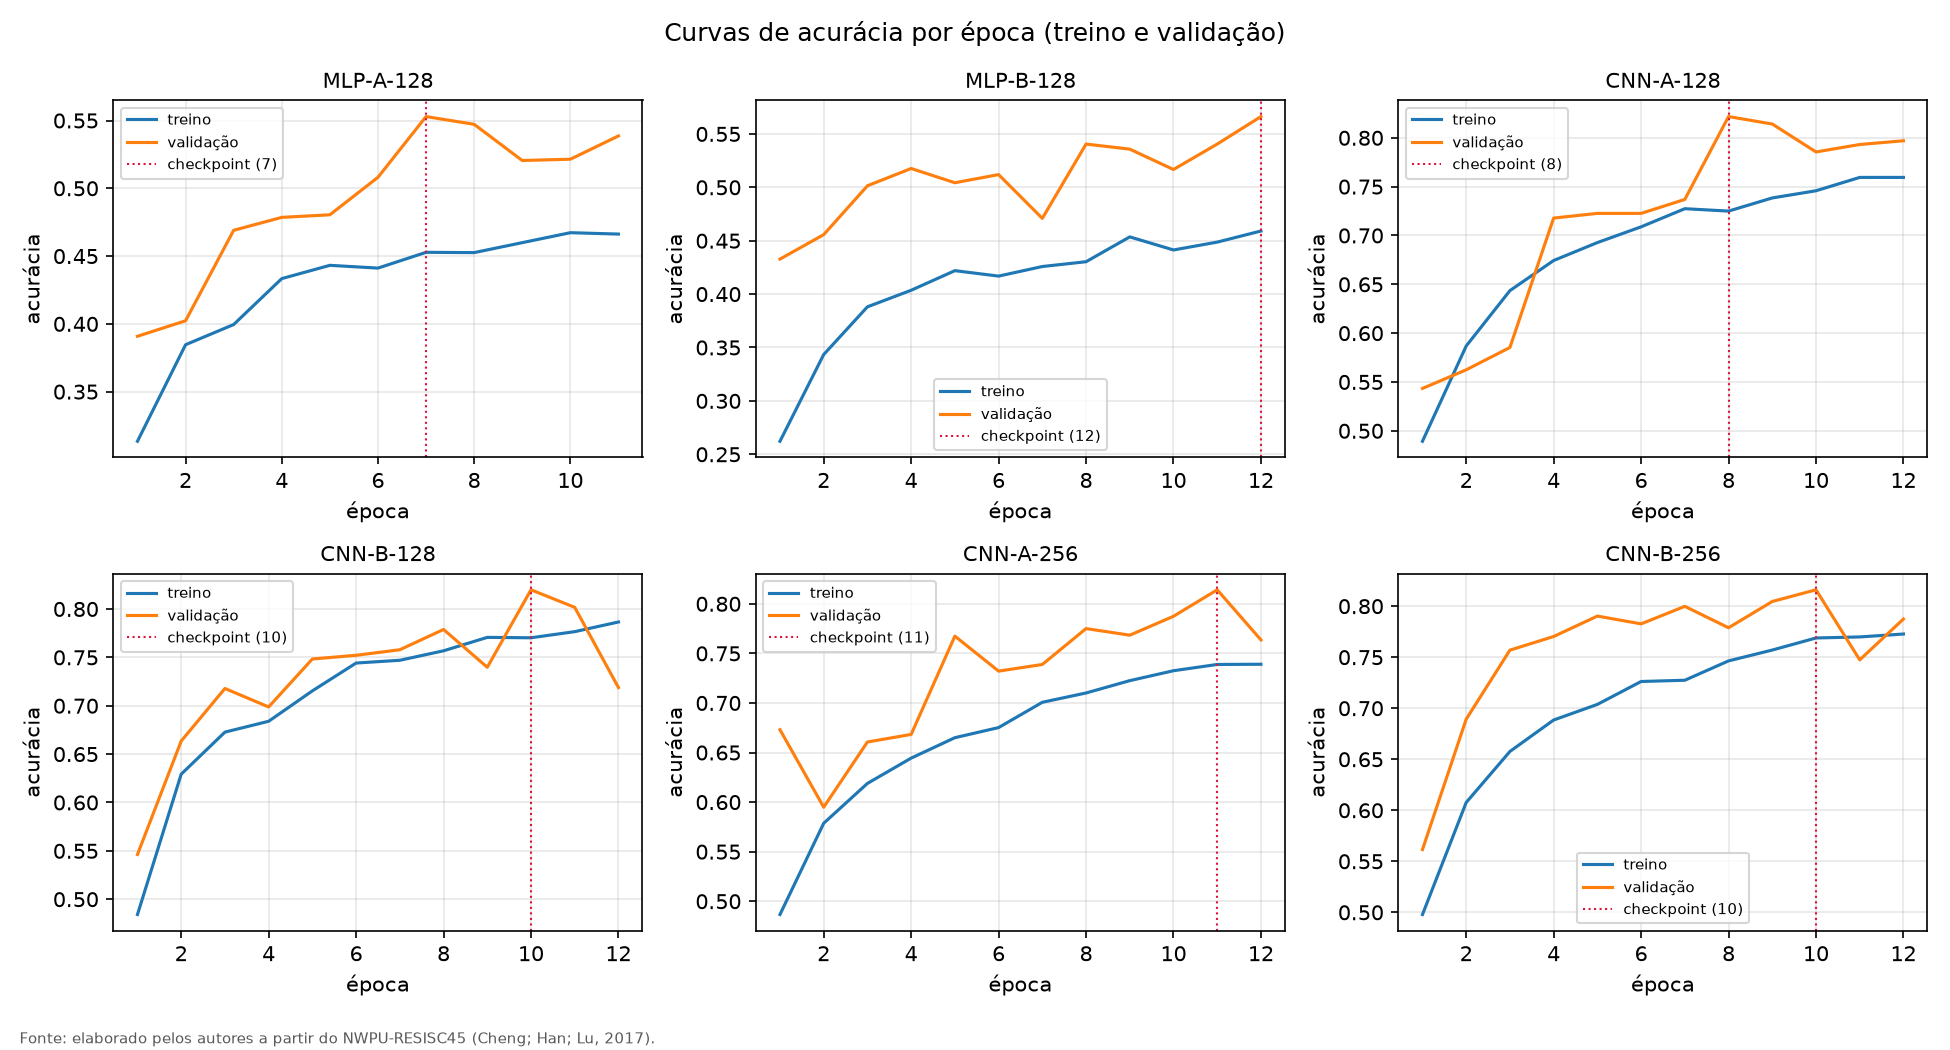

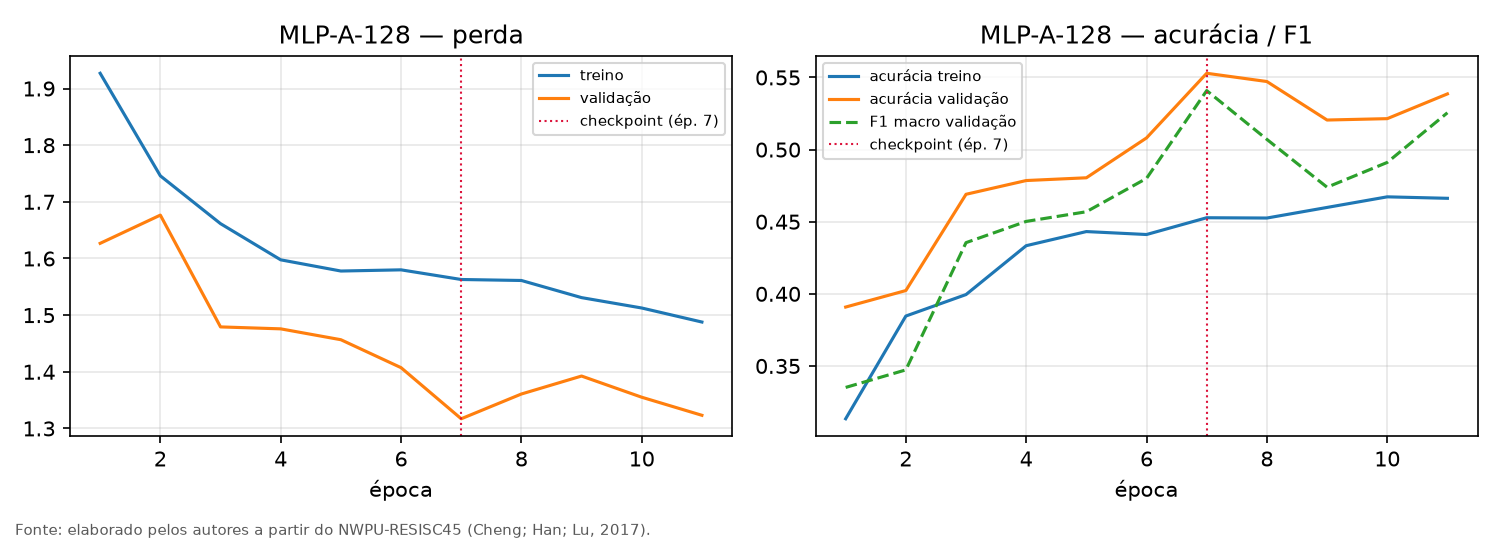

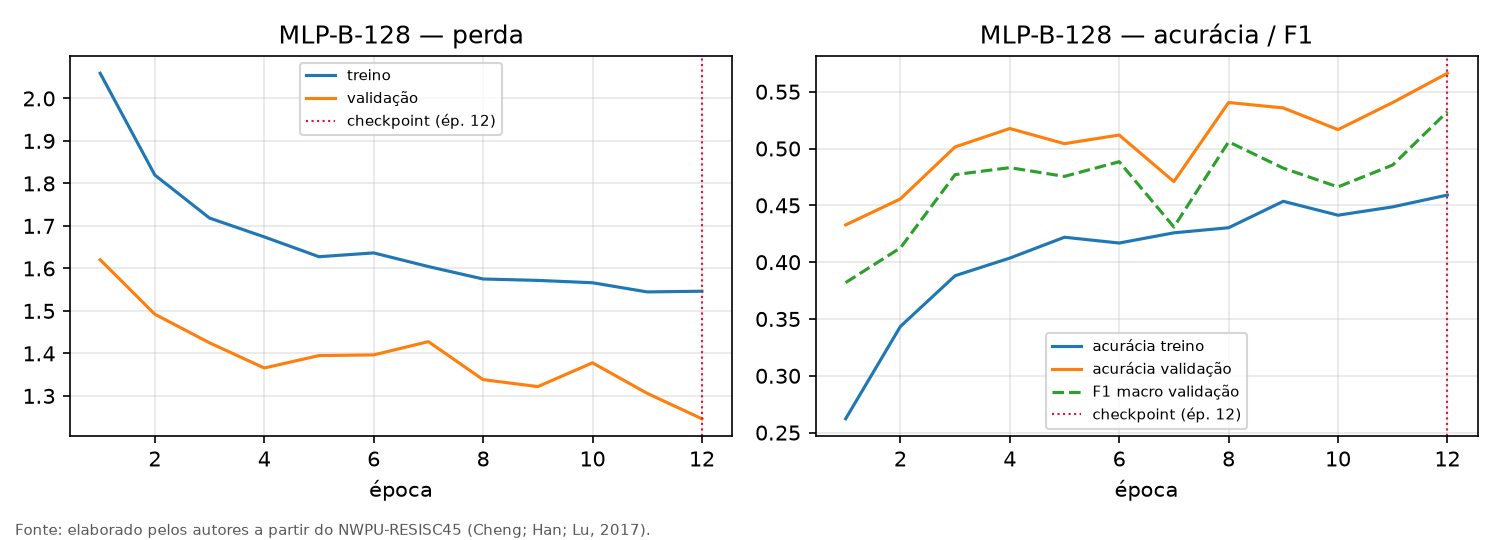

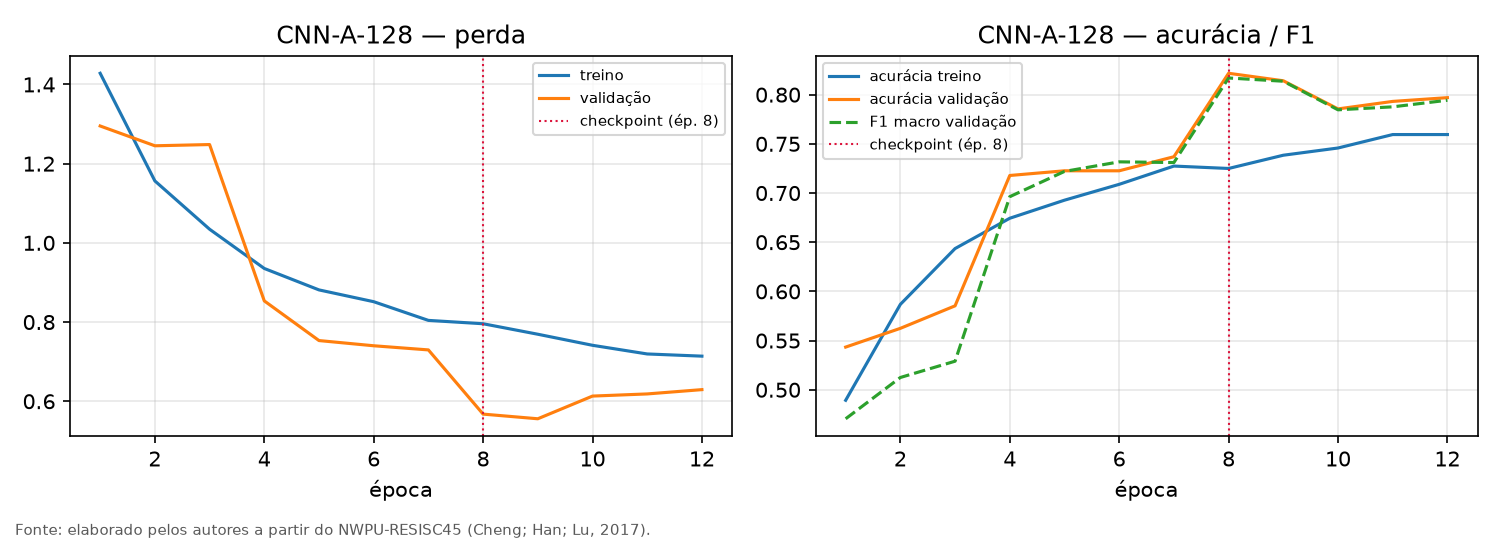

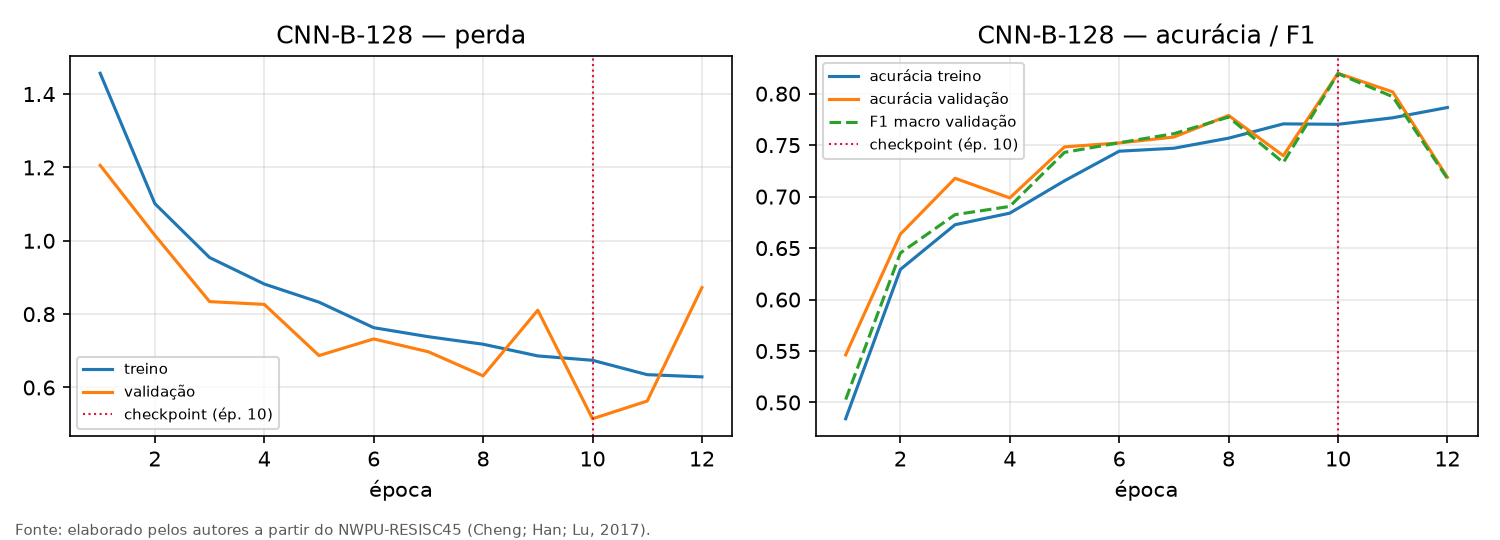

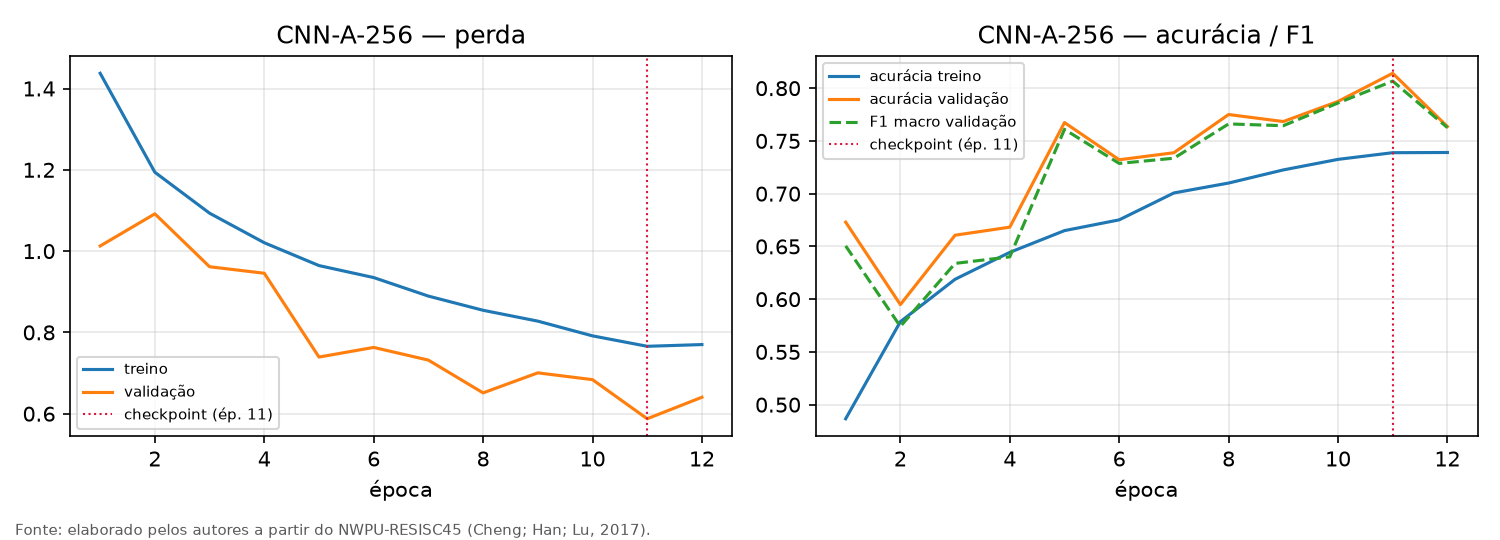

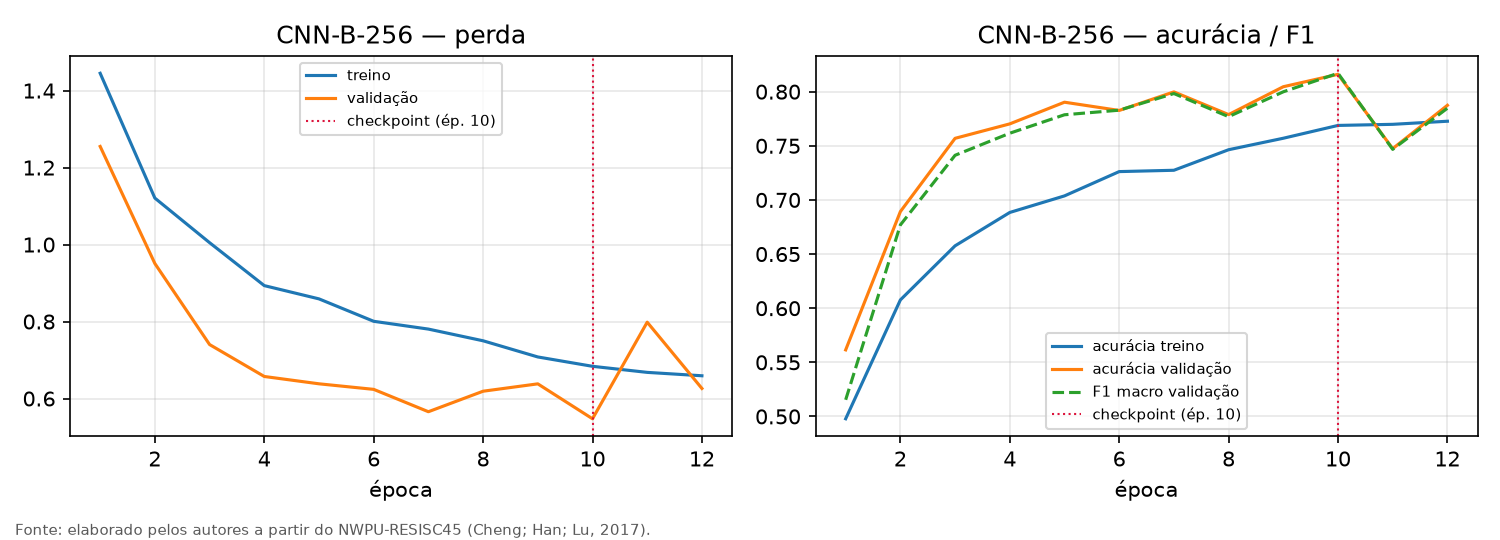

In [5]:
display(Show(FIG / "painel_curvas_perda.png"))
display(Show(FIG / "painel_curvas_acuracia.png"))
for experimento in experimentos["experimento"]:
    display(Show(FIG / f"curvas_{experimento}.png"))

## Métricas por classe


MLP-A-128 (teste)


,classe,precisao,recall,f1,suporte
0,airport,0.405,0.286,0.335,105
1,beach,0.690,0.552,0.614,105
2,circular_farmland,0.504,0.552,0.527,105
3,dense_residential,0.544,0.410,0.467,105
4,desert,0.780,0.876,0.825,105
5,forest,0.680,0.990,0.806,105
6,harbor,0.574,0.552,0.563,105
7,mountain,0.221,0.181,0.199,105
8,river,0.447,0.562,0.498,105
9,storage_tank,0.454,0.467,0.460,105



MLP-B-128 (teste)


,classe,precisao,recall,f1,suporte
0,airport,0.458,0.105,0.170,105
1,beach,0.626,0.686,0.654,105
2,circular_farmland,0.552,0.552,0.552,105
3,dense_residential,0.436,0.648,0.521,105
4,desert,0.769,0.886,0.823,105
5,forest,0.638,0.990,0.776,105
6,harbor,0.574,0.629,0.600,105
7,mountain,0.426,0.190,0.263,105
8,river,0.505,0.467,0.485,105
9,storage_tank,0.411,0.419,0.415,105



CNN-A-128 (teste)


,classe,precisao,recall,f1,suporte
0,airport,0.731,0.724,0.727,105
1,beach,0.887,0.819,0.852,105
2,circular_farmland,0.856,0.905,0.880,105
3,dense_residential,0.790,0.933,0.856,105
4,desert,0.782,0.886,0.830,105
5,forest,0.866,0.981,0.920,105
6,harbor,0.933,0.924,0.928,105
7,mountain,0.898,0.419,0.571,105
8,river,0.587,0.800,0.677,105
9,storage_tank,0.925,0.705,0.800,105


... (2 outputs left out)


CNN-A-256 (teste)


,classe,precisao,recall,f1,suporte
0,airport,0.831,0.562,0.670,105
1,beach,0.927,0.848,0.886,105
2,circular_farmland,0.710,0.933,0.807,105
3,dense_residential,0.978,0.867,0.919,105
4,desert,0.727,0.914,0.810,105
5,forest,0.936,0.971,0.953,105
6,harbor,0.927,0.962,0.944,105
7,mountain,0.632,0.638,0.635,105
8,river,0.714,0.524,0.604,105
9,storage_tank,0.815,0.924,0.866,105



CNN-B-256 (teste)


,classe,precisao,recall,f1,suporte
0,airport,0.635,0.762,0.693,105
1,beach,0.978,0.838,0.903,105
2,circular_farmland,0.921,0.781,0.845,105
3,dense_residential,0.855,0.952,0.901,105
4,desert,0.894,0.886,0.890,105
5,forest,0.896,0.905,0.900,105
6,harbor,0.990,0.943,0.966,105
7,mountain,0.570,0.819,0.672,105
8,river,0.790,0.467,0.587,105
9,storage_tank,0.848,0.848,0.848,105


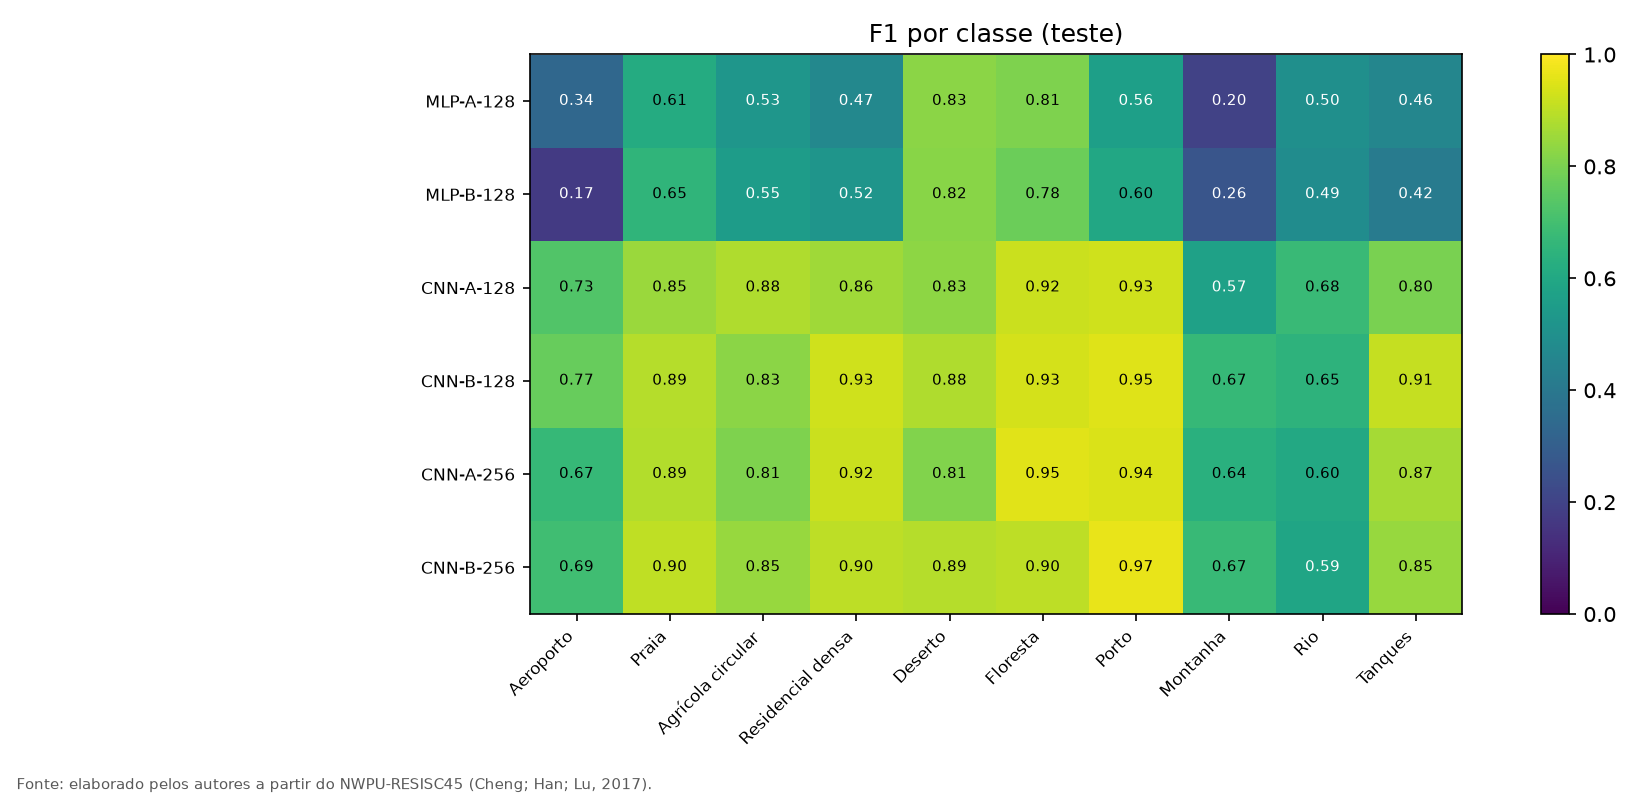

In [6]:
for experimento in experimentos["experimento"]:
    tabela = pd.read_csv(ROOT / "resultados/metricas" / f"{experimento}_{alvo}_por_classe.csv")
    print(f"\n{experimento} ({alvo})")
    display(tabela.round(3))
display(Show(FIG / f"f1_por_classe_{alvo}.png"))

## Matrizes de confusão (reais nas linhas, previstas nas colunas)

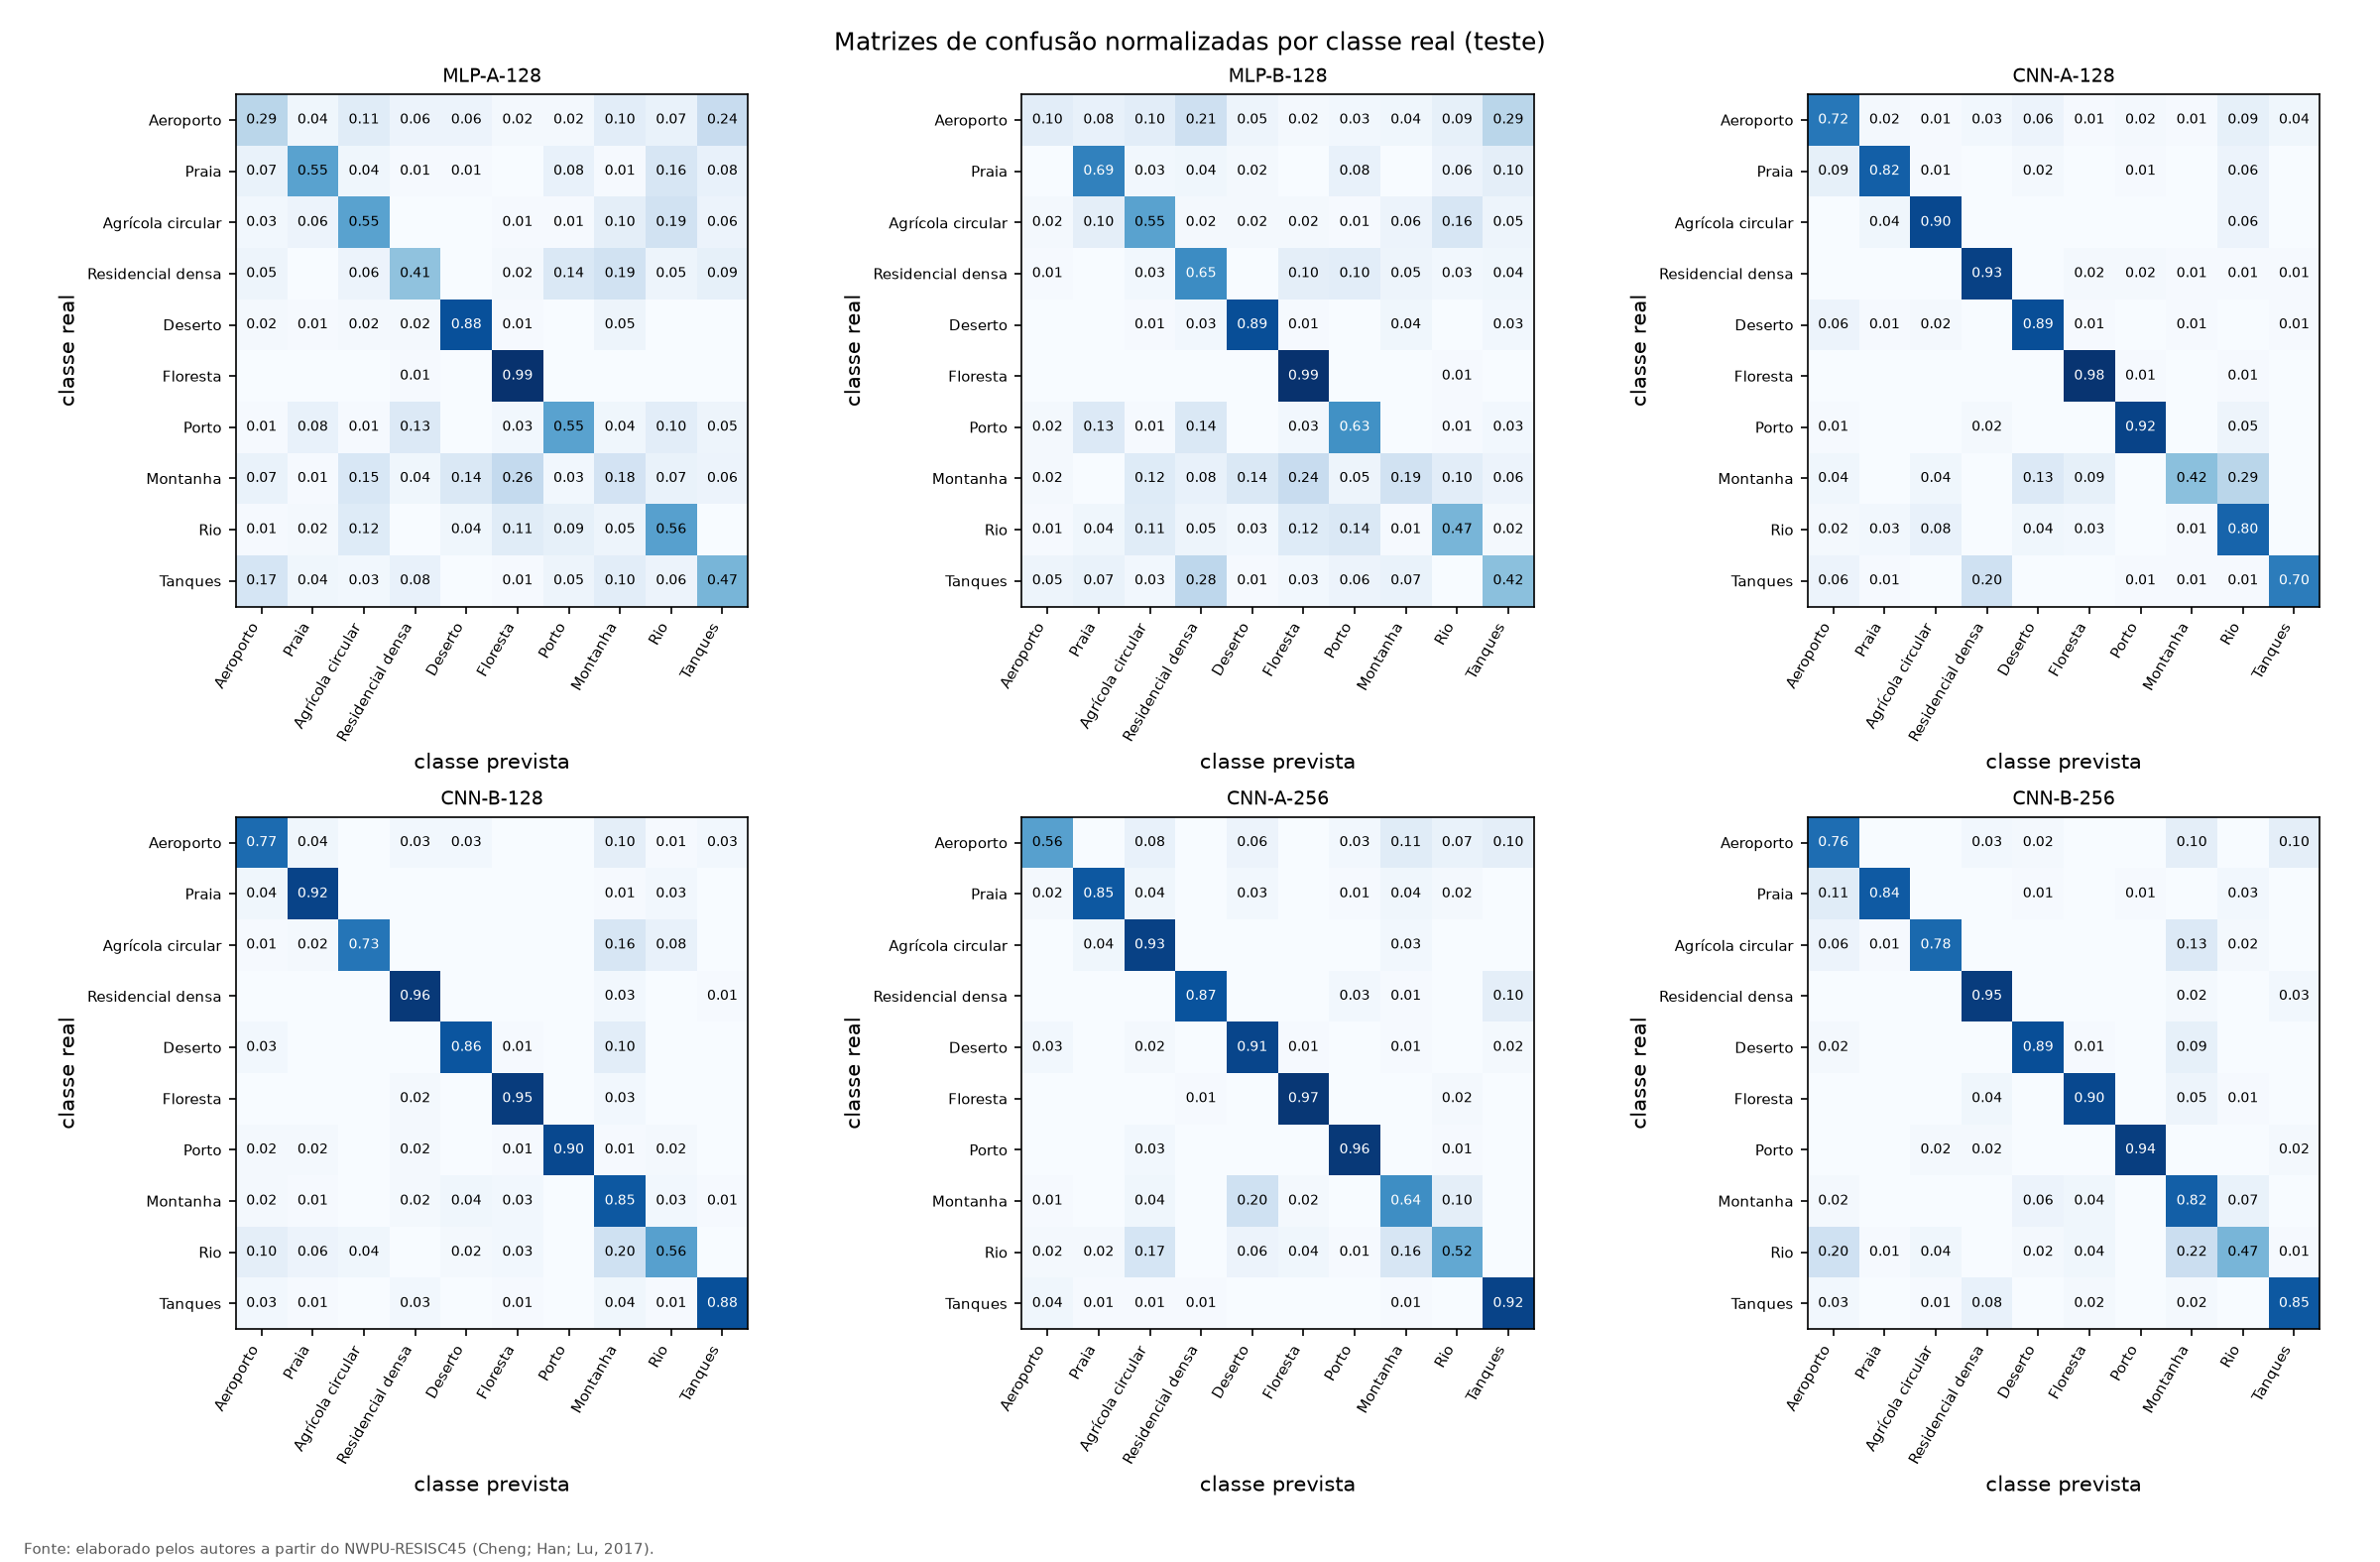

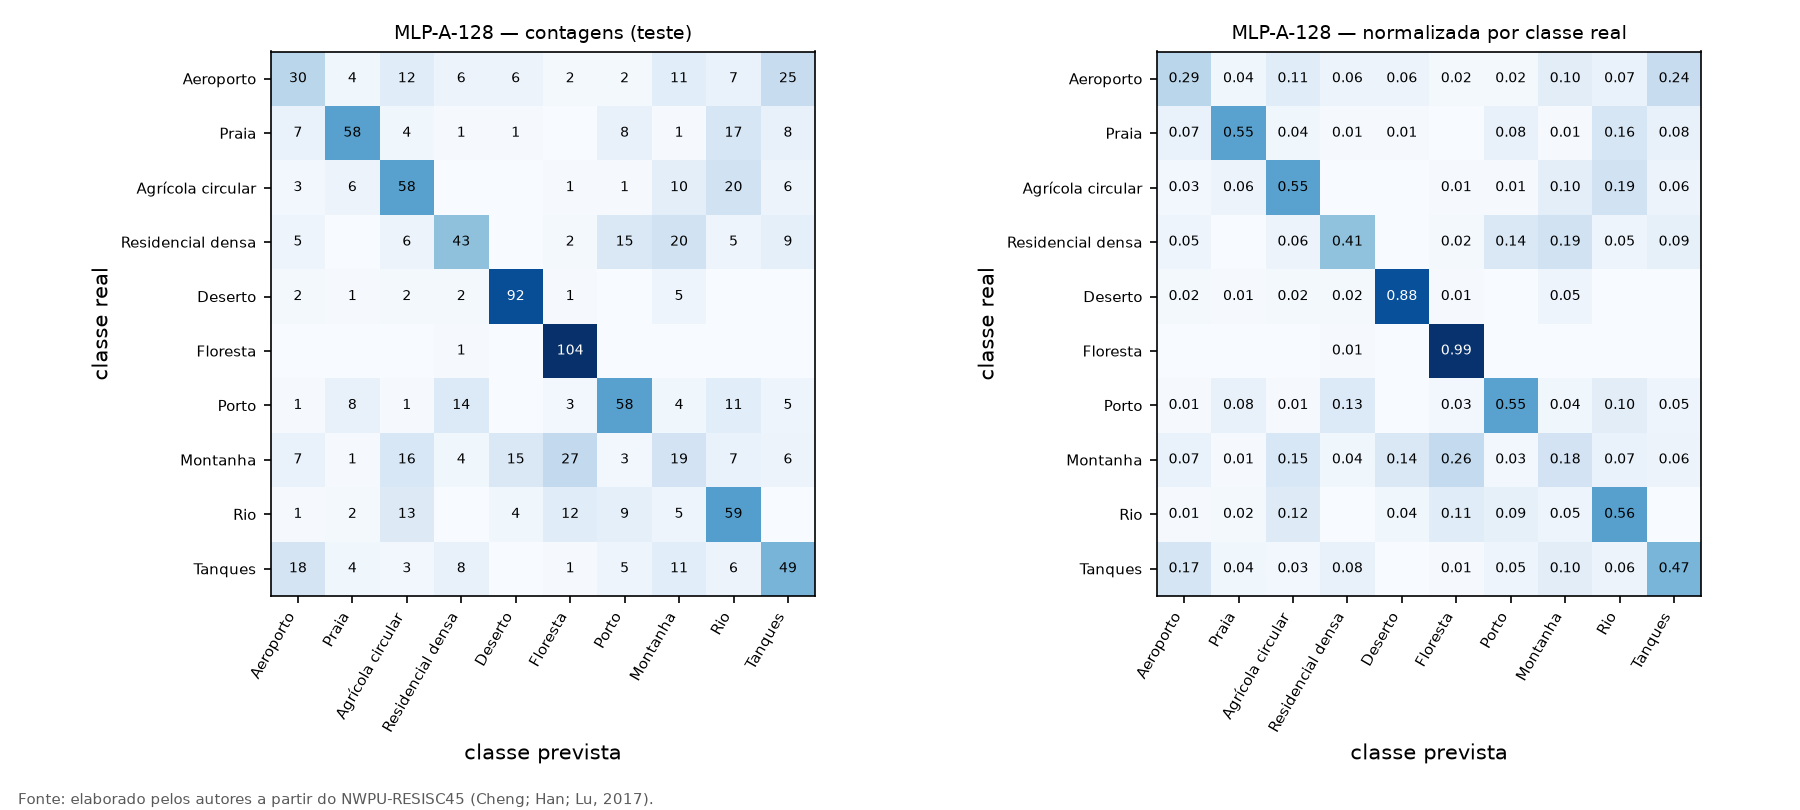

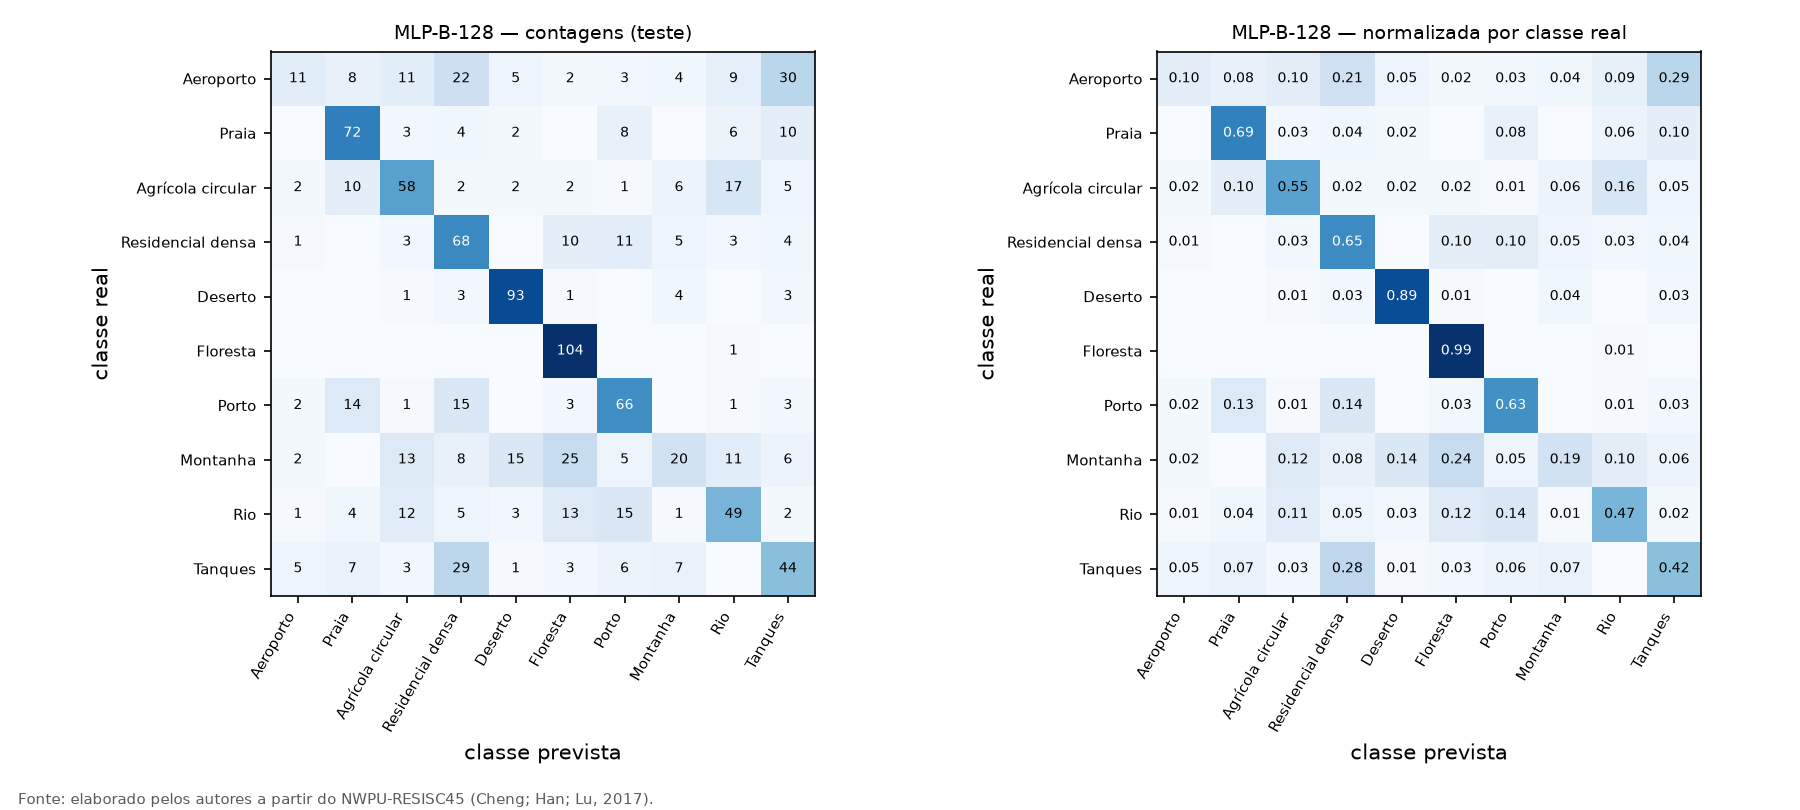

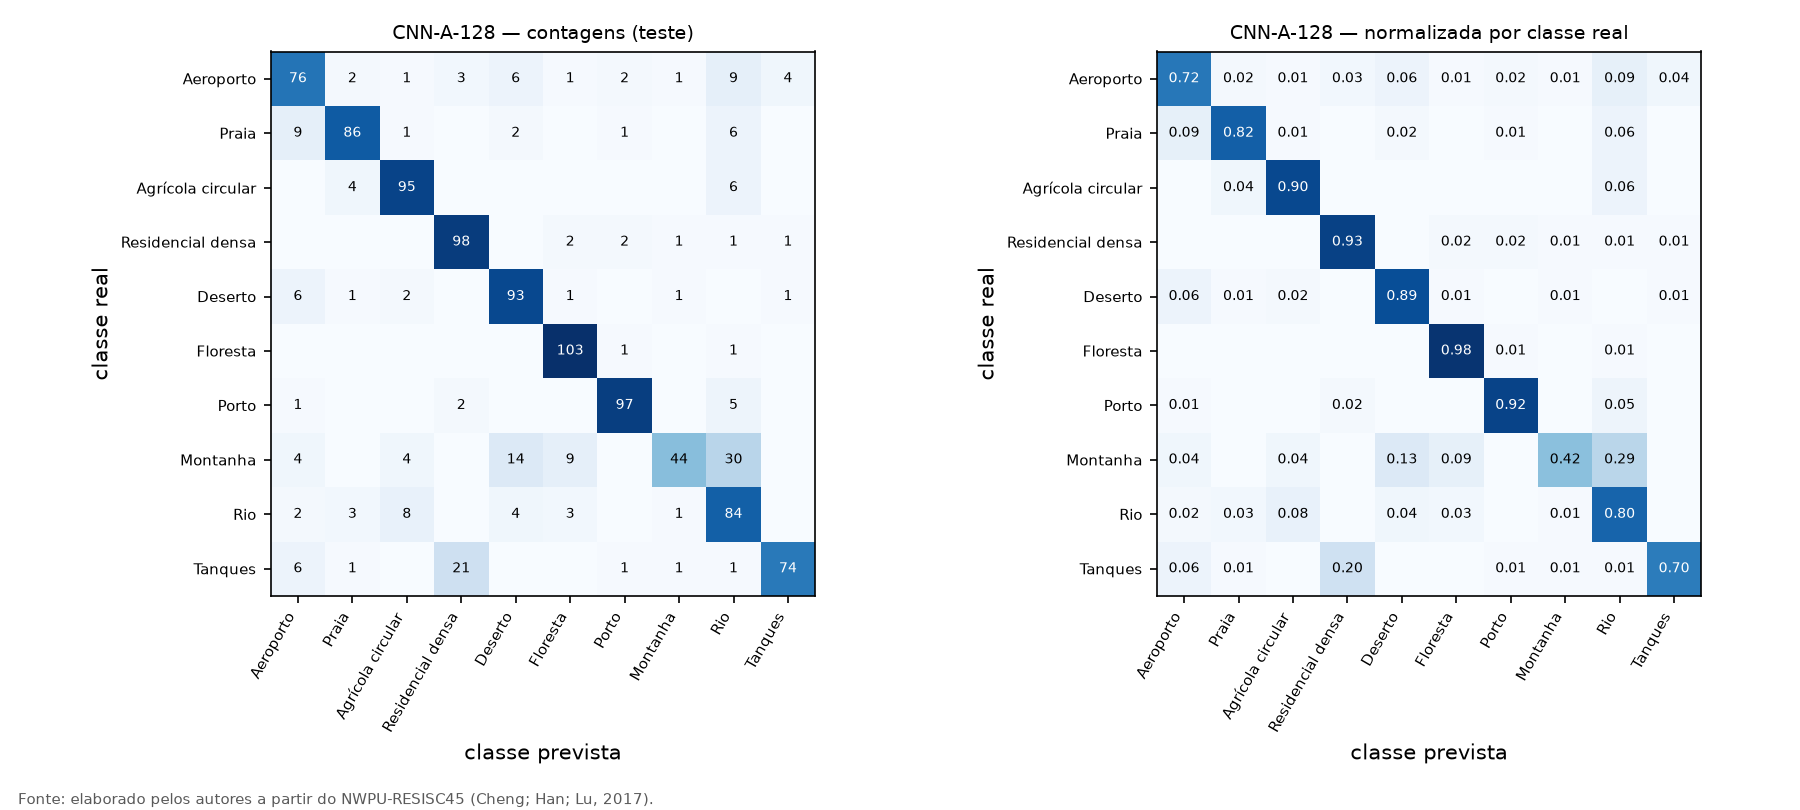

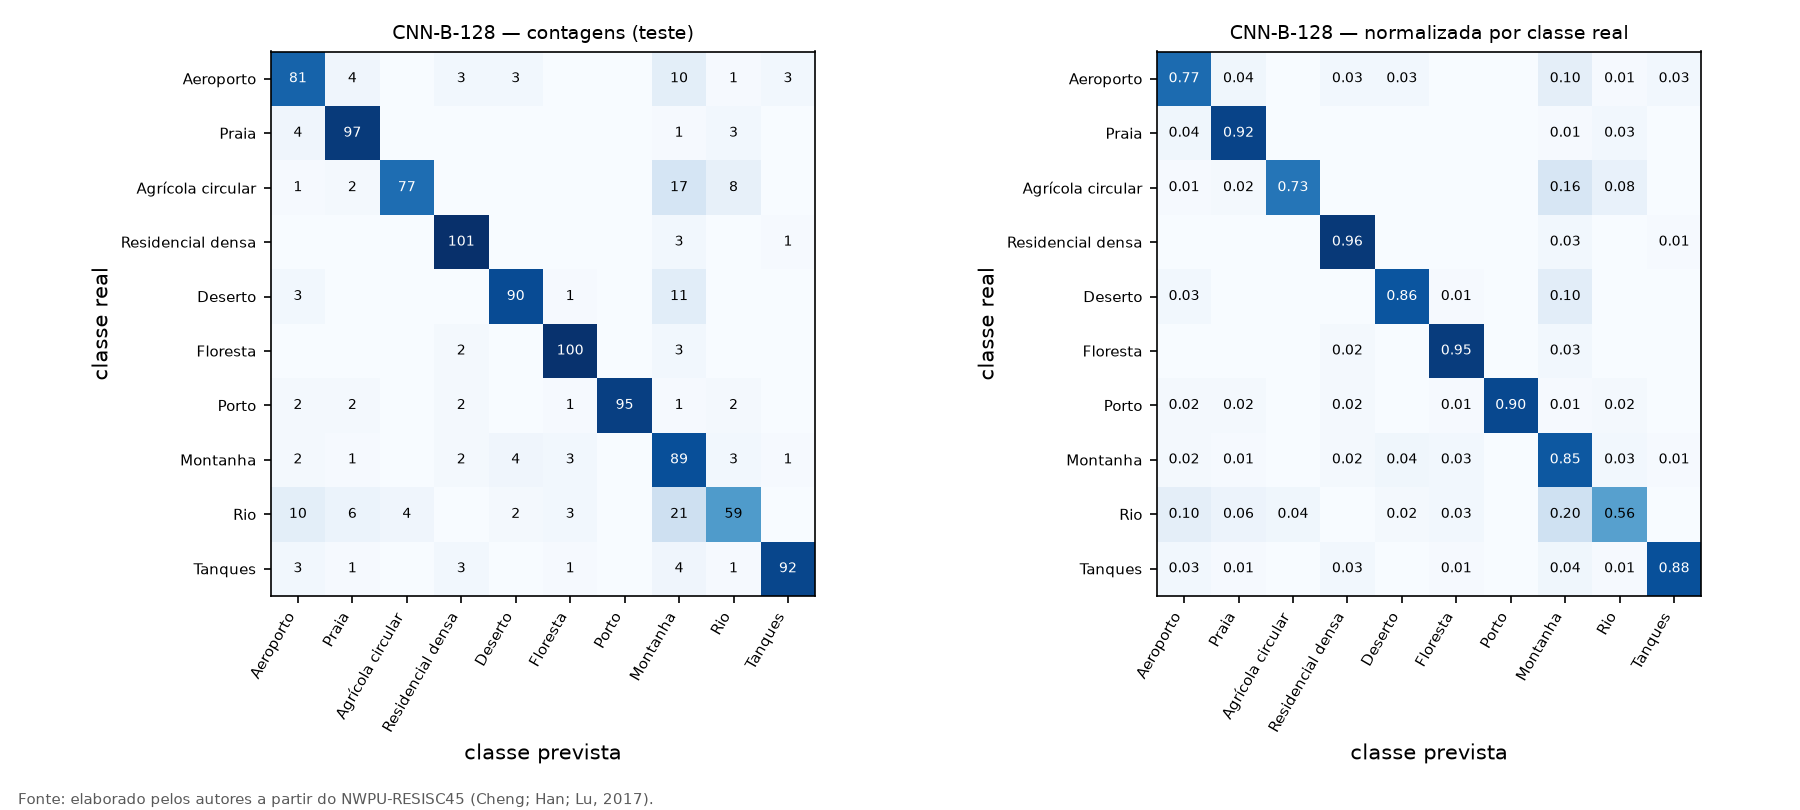

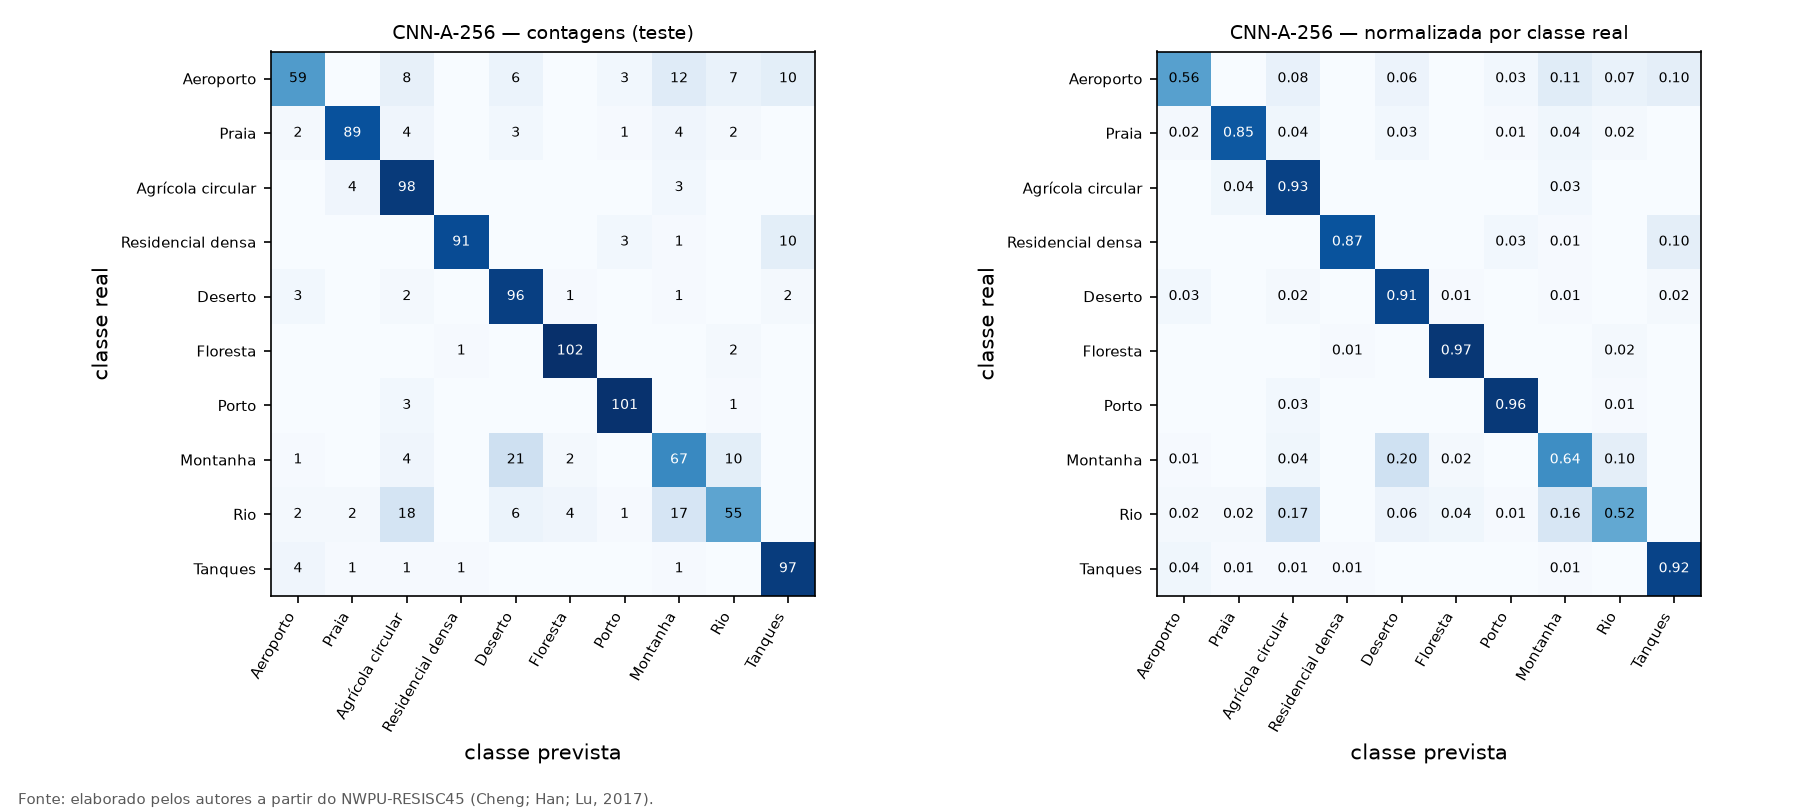

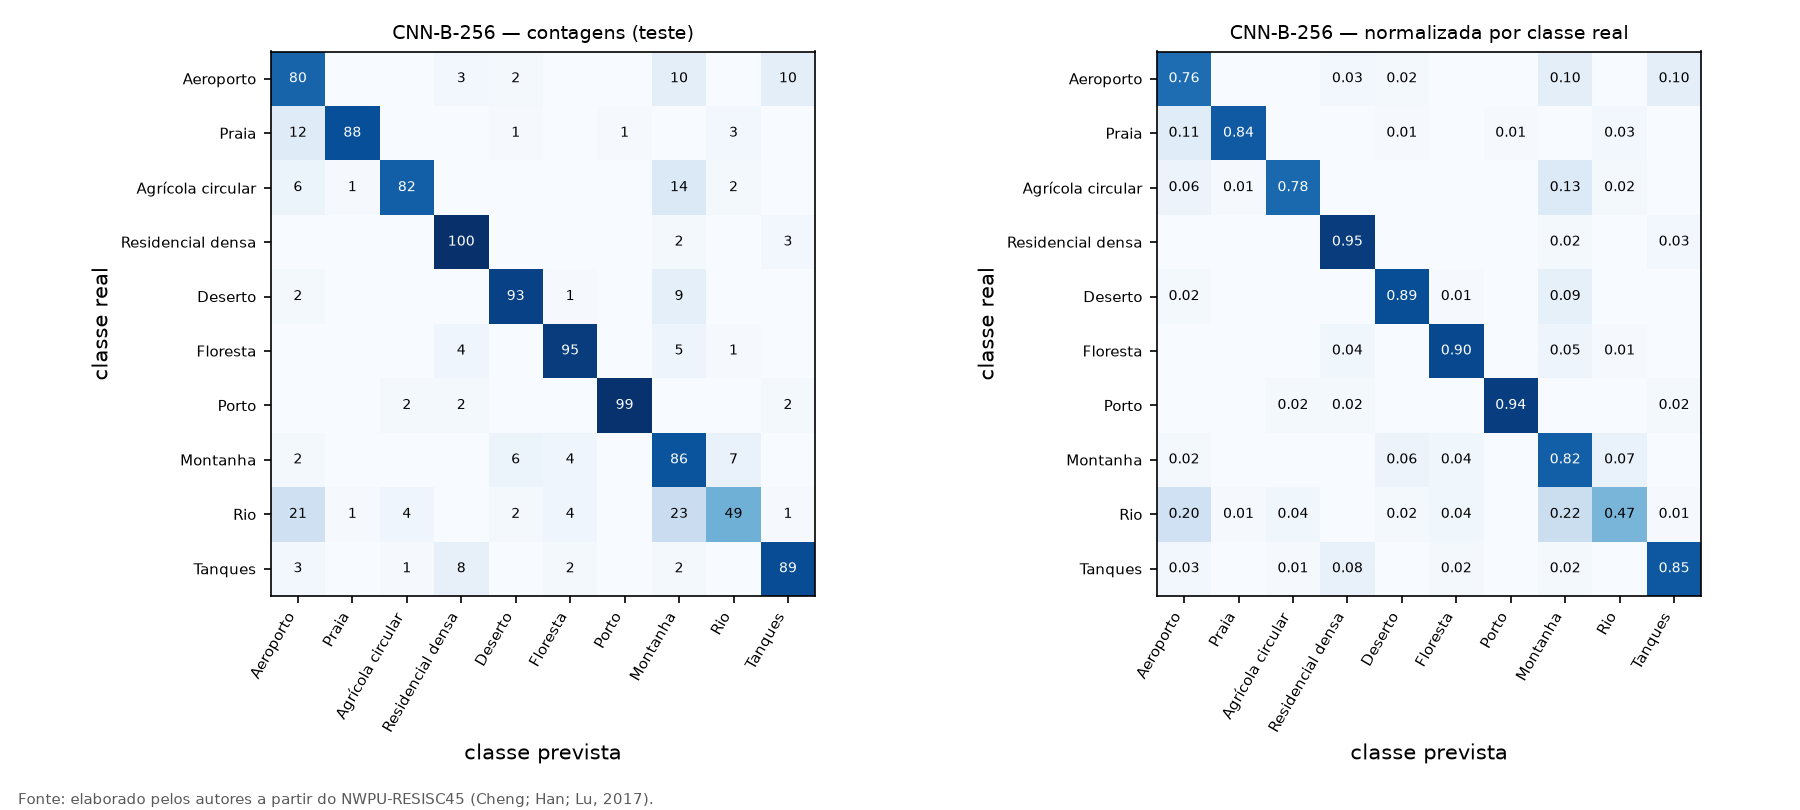

In [7]:
display(Show(FIG / f"painel_confusao_{alvo}.png"))
for experimento in experimentos["experimento"]:
    display(Show(FIG / f"confusao_{experimento}_{alvo}.png"))

In [8]:
# Pares de classes mais confundidos (fora da diagonal), somando os seis modelos
total = None
for experimento in experimentos["experimento"]:
    m = pd.read_csv(ROOT / "resultados/metricas" / f"{experimento}_{alvo}_confusao.csv", index_col=0)
    total = m if total is None else total + m
fora = [(total.loc[r, p], r, p) for r in CLASSES for p in CLASSES if r != p]
pd.DataFrame(sorted(fora, reverse=True)[:10], columns=["erros", "real", "prevista"])

,erros,real,prevista
0,82,airport,storage_tank
1,75,mountain,desert
2,70,storage_tank,dense_residential
3,70,mountain,forest
4,68,river,mountain
5,68,mountain,river
6,59,river,circular_farmland
7,53,circular_farmland,river
8,50,circular_farmland,mountain
9,48,airport,mountain


## Análise de erros (modelo de maior F1 macro de validação)

{'modelo_analise_erros': 'CNN-B-128', 'criterio': 'maior F1 macro de validação'}


,experimento,arquivo,classe_real,classe_prevista,confianca
0,CNN-B-128,dados/raw/NWPU-RESISC45/desert/desert_614.jpg,desert,forest,0.996148
1,CNN-B-128,dados/raw/NWPU-RESISC45/desert/desert_274.jpg,desert,mountain,0.995987
2,CNN-B-128,dados/raw/NWPU-RESISC45/desert/desert_543.jpg,desert,mountain,0.993104
3,CNN-B-128,dados/raw/NWPU-RESISC45/storage_tank/storage_t...,storage_tank,dense_residential,0.982587
4,CNN-B-128,dados/raw/NWPU-RESISC45/airport/airport_229.jpg,airport,dense_residential,0.979757
5,CNN-B-128,dados/raw/NWPU-RESISC45/river/river_013.jpg,river,forest,0.975169


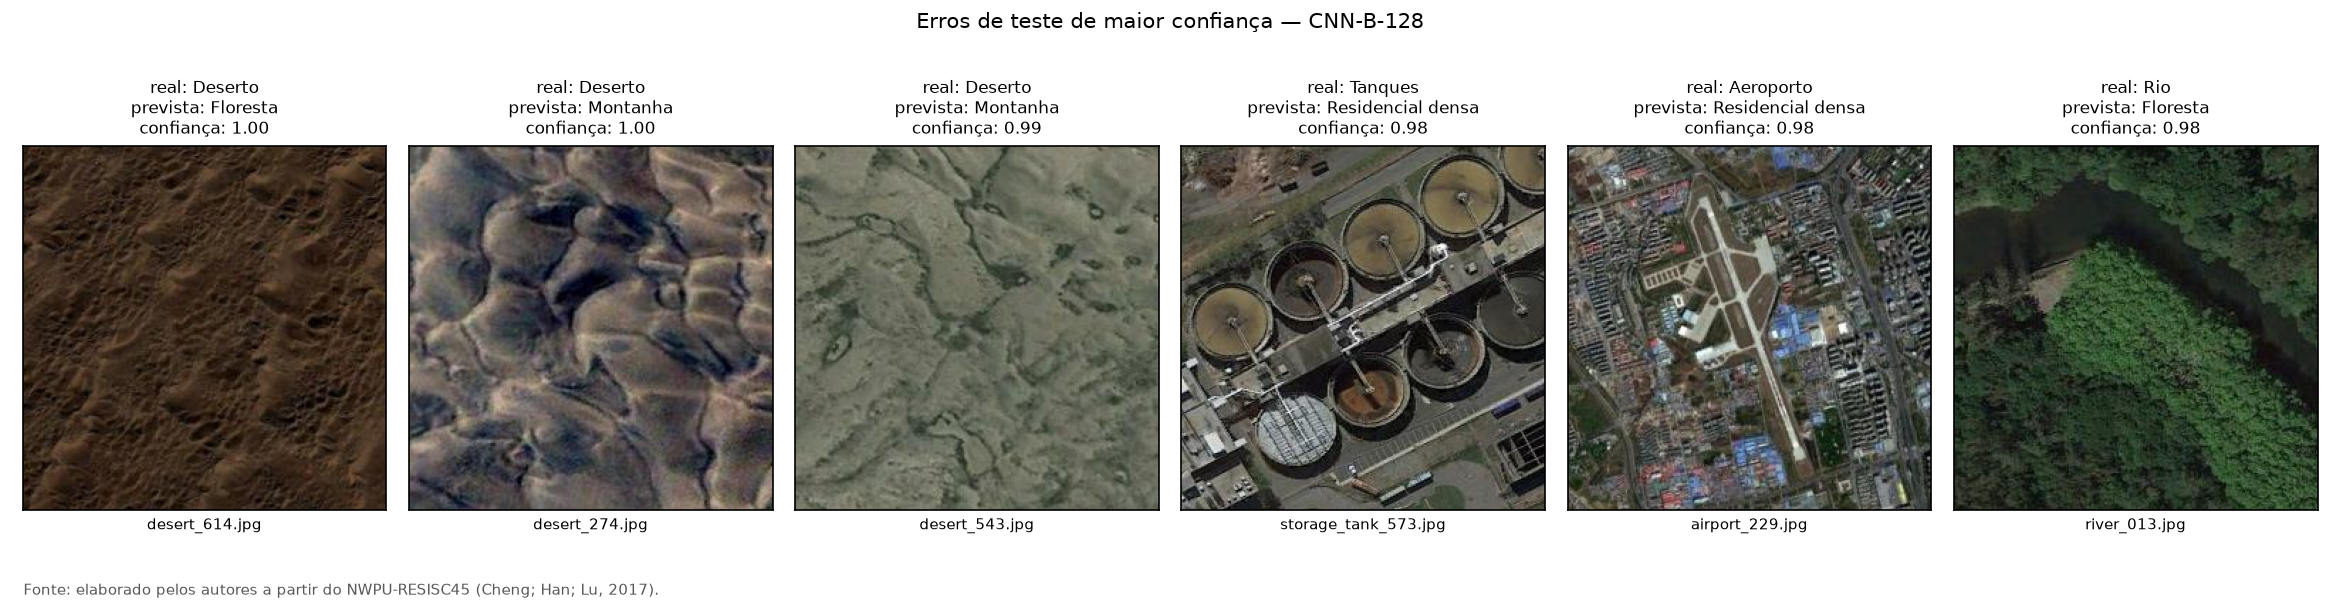

In [9]:
if tem_teste:
    print(json.loads((ROOT / "resultados/selecao.json").read_text(encoding="utf-8")))
    display(pd.read_csv(ROOT / "resultados/erros_teste.csv"))
    display(Show(FIG / "erros_teste.png"))
    if (FIG / "erros_teste_YOLO-cls.png").exists():
        display(Show(FIG / "erros_teste_YOLO-cls.png"))
else:
    print("Teste ainda não avaliado.")

## Roteiro da discussão (para o artigo)

1. Como MLP A/B e CNN A/B se comportaram em 128×128? A profundidade ajudou a MLP? O viés indutivo da convolução compensou?
2. Como a resolução 256×256 afetou cada CNN (desempenho, tempo por época, memória)? O campo receptivo fixo cobre metade da
   cena em 256 px — isso favorece a CNN B, mais profunda?
3. Os ganhos compensaram o custo (tempo total, tempo/época, parâmetros, tamanho do arquivo)?
4. Quais classes foram confundidas e quais aspectos visuais explicam (água/areia, textura de relevo, estruturas circulares)?
5. Curvas: há subajuste (perdas altas e próximas) ou sobreajuste (treino cai, validação sobe)? Em que época?
6. Limites de generalização: um único treino por configuração, sensores/regiões/estações diferentes, resolução espacial
   variável do RESISC45 (≈0,2 a 30 m/pixel).